In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('Telco_Customer_Churn.csv')

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape

(7043, 21)

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [25]:
df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ','_')

In [26]:
df['totalcharges'] = pd.to_numeric(df['totalcharges'], errors='coerce')

In [27]:
df['totalcharges'].isnull().sum()

np.int64(11)

In [35]:
df = df.dropna(subset=['totalcharges'])

In [28]:
df['churn'].value_counts()

churn
No     5174
Yes    1869
Name: count, dtype: int64

Text(0.5, 1.0, 'Churn Distribution')

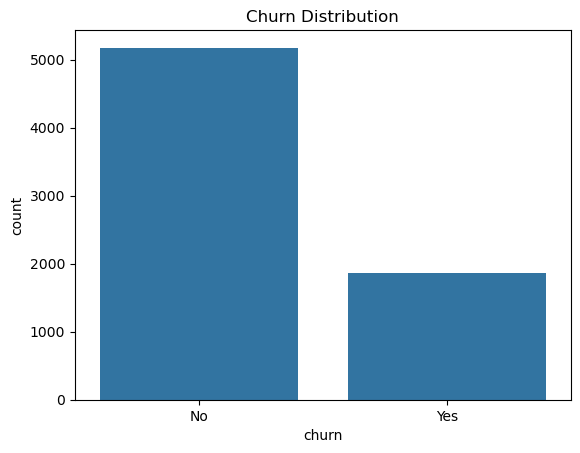

In [29]:
#churn distrubution
sns.countplot(x='churn', data=df)
plt.title('Churn Distribution')

Text(0.5, 1.0, 'Distribution of Tenure')

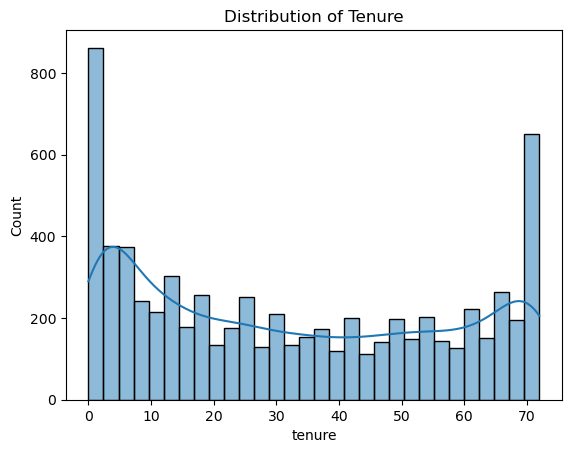

In [30]:
#tenure distribution
sns.histplot(df['tenure'], bins=30, kde=True)
plt.title('Distribution of Tenure')

Text(0.5, 1.0, 'Distribution of Monthly Charges')

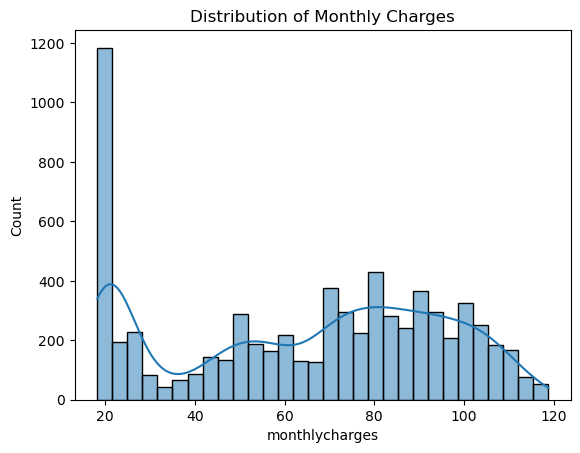

In [31]:
#monthly charges distribution
sns.histplot(df['monthlycharges'], bins=30, kde=True)
plt.title('Distribution of Monthly Charges')

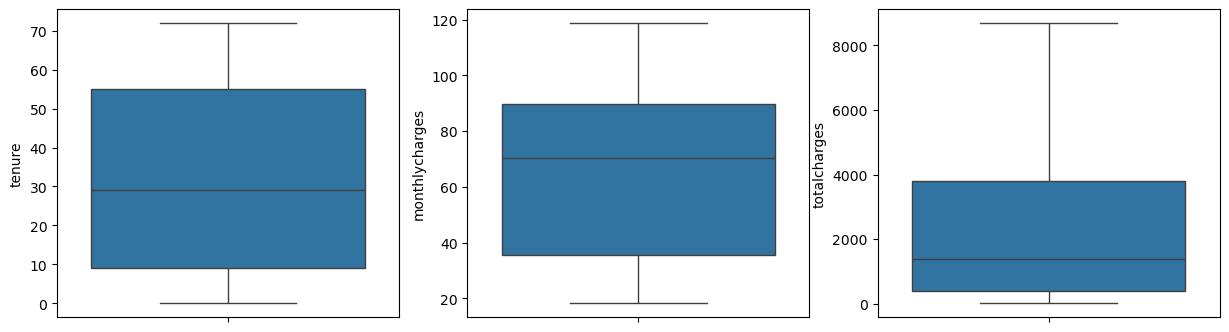

In [32]:
#outlier check
fig, axes = plt.subplots(1, 3, figsize=(15,4))
sns.boxplot(y=df['tenure'], ax=axes[0])
sns.boxplot(y=df['monthlycharges'], ax=axes[1])
sns.boxplot(y=df['totalcharges'], ax=axes[2])
plt.show()

<Axes: >

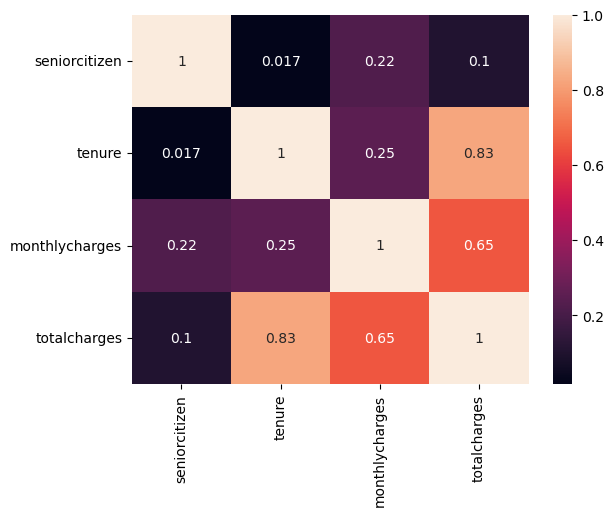

In [33]:
#correlation heatmap
sns.heatmap(df.corr(numeric_only = True), annot=True)

In [12]:
from sqlalchemy import create_engine
from urllib.parse import quote_plus

In [13]:
#mysql connection
username = 'root'
password = quote_plus('root@123')
host = 'localhost'
port = '3306'
database = 'telcodatabase'

engine = create_engine(f"mysql+pymysql://{username}:{password}@{host}:{port}/{database}")

#write datafram to mysql
table_name = 'telco'
df.to_sql(table_name, engine, if_exists = 'replace', index = False)

#read back sample
pd.read_sql('SELECT * FROM telco LIMIT 5;', engine)

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
